<div style="text-align: center;">

  <img src="img/LogoUesc.png" alt="UESC" style="width: 60px; display: block; margin: 0 auto 5px auto;">

  <div style="font-size: 20px;"><strong>UNIVERSIDADE ESTADUAL DE SANTA CRUZ - UESC</strong></div>
  <div style="font-size: 18px;">DEPARTAMENTO DE ENGENHARIAS E COMPUTAÇÃO - DEC</div>
  <div style="font-size: 18px;">Grupo de Pesquisas em Simulações e Controle de Processos</div>

  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

  <div style="font-size: 22px; font-weight: bold; margin-bottom: 10px;">PROGRAMAÇÃO EM PYTHON PARA AS ENGENHARIAS</div>

  <div style="font-size: 18px; margin-top: 10px;"><strong>Tema</strong>: Balanços de Massa e Energia com Python — Modelagem de Processos Químicos.</div>
  <div style="font-size: 18px;"><strong>Prof.  Dr.  E. R. Edwards</strong></div>

  <div style="font-size: 16px; margin-top: 15px;">Ilhéus - BA, Abril de 2027</div>
  
  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

</div>

**Apresentação**

Os balanços de massa e de energia traduzem as leis de conservação em equações capazes de descrever e prever o comportamento dos processos químicos. Neste notebook, a programação é utilizada como consequência da modelagem: identificamos o sistema, estabelecemos as hipóteses, escrevemos os balanços, resolvemos casos simples manualmente e implementamos algoritmos em Python.

Os exemplos abordam misturadores, tanques, aquecimento, reação química e trocadores de calor. Os parâmetros são **didáticos** e não substituem dados de projeto, procedimentos operacionais ou avaliação de segurança.

**Objetivos de aprendizagem:** formular balanços globais e de componentes, distinguir regimes estacionário e transiente, construir balanços de energia, simular equações diferenciais e verificar coerência dimensional e física.

**Sumário**

1. [O papel dos balanços na Engenharia Química](#secao-1)
2. [Sistema, fronteira e hipóteses de modelagem](#secao-2)
3. [Balanço global de massa em regime estacionário](#secao-3)
4. [Balanço de componentes em um misturador](#secao-4)
5. [Balanço de massa em um tanque dinâmico](#secao-5)
6. [Mistura em tanque de volume constante](#secao-6)
7. [Balanço com reação química e estequiometria](#secao-7)
8. [Balanço de energia: conceitos e unidades](#secao-8)
9. [Aquecimento sensível em processo contínuo](#secao-9)
10. [Mistura adiabática de correntes](#secao-10)
11. [Balanço de energia em tanque aquecido](#secao-11)
12. [Simulação numérica com o método de Euler](#secao-12)
13. [Simulação com solve_ivp e verificação](#secao-13)
14. [Trocador de calor: balanços das correntes](#secao-14)
15. [Análise de sensibilidade e interpretação](#secao-15)
16. [Validação física e erros frequentes](#secao-16)
17. [Exercícios de consolidação](#secao-17)
18. [Conclusões](#secao-18)

<div id="secao-1" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">1. O papel dos balanços na Engenharia Química</div>

Em um processo industrial, o balanço é uma ferramenta para responder perguntas concretas: qual vazão sai de um misturador? Como varia a concentração em um tanque? Qual potência é necessária para aquecer uma corrente? A resposta depende das fronteiras escolhidas, dos mecanismos de transporte e das hipóteses adotadas.

A forma geral de uma conservação é

$$\boxed{\text{Acúmulo}=\text{Entrada}-\text{Saída}+\text{Geração}-\text{Consumo}}.$$

Para **massa total**, não há geração nem consumo em reações químicas usuais. Para **componentes químicos**, pode haver formação e consumo por reação. Para **energia**, os termos relevantes incluem transporte por correntes, calor, trabalho e variações de energia armazenada.

<div id="secao-2" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">2. Sistema, fronteira e hipóteses de modelagem</div>

Antes de escrever equações, devemos definir um **volume de controle**: região do espaço atravessada por correntes de entrada e saída. A fronteira delimita o que será contabilizado no balanço.

Neste notebook, indicaremos explicitamente quando assumimos mistura perfeita, propriedades constantes, ausência de reação, perdas térmicas desprezíveis ou pressão aproximadamente constante. Essas simplificações não são propriedades universais dos processos.

**Verificação dimensional:** vazão mássica em kg/s, vazão volumétrica em L/min ou m³/s, concentração em g/L, entalpia específica em J/kg, potência em W = J/s. Antes de somar termos, todos devem estar em unidades compatíveis.

<div id="secao-3" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">3. Balanço global de massa em regime estacionário</div>

**Problema de Engenharia — Separação de correntes.** Um equipamento recebe 120 kg/h de mistura e descarrega duas correntes. Uma delas tem vazão de 45 kg/h. Em regime estacionário, sem acumulação e sem outras entradas ou saídas,

$$0=\dot m_{in}-\dot m_1-\dot m_2.$$

Logo, $\dot m_2=120-45=75\ \mathrm{kg/h}$. Vamos implementar o cálculo e conferir o fechamento do balanço.

In [1]:
m_entrada = 120.0  # kg/h
m_saida_1 = 45.0  # kg/h
m_saida_2 = m_entrada - m_saida_1
residuo = m_entrada - m_saida_1 - m_saida_2
print(f"Segunda saída: {m_saida_2:.1f} kg/h")
print(f"Resíduo do balanço: {residuo:.2e} kg/h")

Segunda saída: 75.0 kg/h
Resíduo do balanço: 0.00e+00 kg/h


**Interpretação:** a vazão desconhecida é 75 kg/h. O resíduo nulo confirma o fechamento algébrico do balanço com os dados adotados; não comprova a exatidão das medições industriais.

<div id="secao-4" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">4. Balanço de componentes em um misturador</div>

**Problema de Engenharia — Misturador de soluções.** Duas correntes de um soluto diluído, com vazões $Q_1=2$ L/min e $Q_2=3$ L/min, apresentam concentrações $C_1=10$ g/L e $C_2=4$ g/L. Admitindo volumes aditivos, densidades compatíveis, ausência de reação e mistura homogênea,

$$Q_s=Q_1+Q_2,\qquad Q_sC_s=Q_1C_1+Q_2C_2.$$

A resolução manual fornece $Q_s=5$ L/min e

$$C_s=\frac{2(10)+3(4)}{5}=6{,}4\ \mathrm{g/L}.$$

Podemos estudar várias combinações de vazões com operações vetoriais.

In [2]:
import numpy as np
Q1 = np.array([2.0, 3.0, 4.0])  # L/min
Q2 = np.array([3.0, 2.0, 1.0])  # L/min
C1, C2 = 10.0, 4.0             # g/L
Q_saida = Q1 + Q2
C_saida = (Q1*C1 + Q2*C2)/Q_saida
for i, (q, c) in enumerate(zip(Q_saida, C_saida), start=1):
    print(f"Condição {i}: Q = {q:.1f} L/min; C = {c:.2f} g/L")

Condição 1: Q = 5.0 L/min; C = 6.40 g/L
Condição 2: Q = 5.0 L/min; C = 7.60 g/L
Condição 3: Q = 5.0 L/min; C = 8.80 g/L


**Interpretação:** a concentração cresce à medida que aumenta a participação da corrente mais concentrada. Se as vazões forem mássicas, o balanço deve ser formulado com frações mássicas, e não com a mesma expressão volumétrica sem justificativa.

<div id="secao-5" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">5. Balanço de massa em um tanque dinâmico</div>

**Problema de Engenharia — Tanque com nível variável.** Um tanque recebe 5 L/min e descarrega 4 L/min, com volume inicial de 50 L. Admitindo líquido de densidade constante,

$$\frac{dV}{dt}=Q_{in}-Q_{out}=1\ \mathrm{L/min}.$$

A solução analítica é $V(t)=V_0+(Q_{in}-Q_{out})t$. Após 10 min, $V(10)=50+1(10)=60$ L. A solução só é válida enquanto o tanque não atingir limites físicos de capacidade ou operação.

Volume em 10 min: 60.0 L


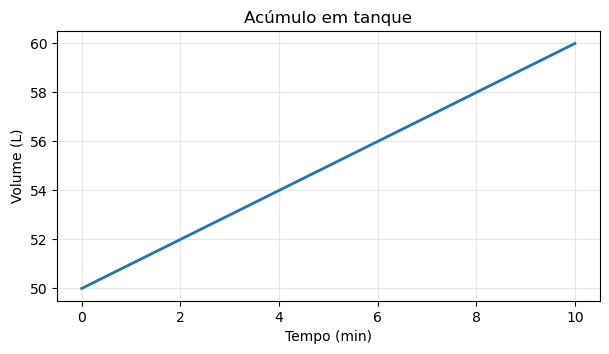

In [3]:
import matplotlib.pyplot as plt
V0, Qin, Qout = 50.0, 5.0, 4.0
tempo_min = np.linspace(0, 10, 101)
volume_L = V0 + (Qin - Qout)*tempo_min
print(f"Volume em 10 min: {volume_L[-1]:.1f} L")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tempo_min, volume_L, linewidth=2)
ax.set(xlabel="Tempo (min)", ylabel="Volume (L)", title="Acúmulo em tanque")
ax.grid(alpha=0.3)
plt.show()

**Interpretação:** o gráfico é linear porque a diferença entre as vazões foi considerada constante. A inclinação corresponde à taxa de acúmulo, em L/min.

<div id="secao-6" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">6. Mistura em tanque de volume constante</div>

**Problema de Engenharia — Diluição dinâmica.** Considere agora um tanque perfeitamente misturado, de volume constante $V=100$ L, com $Q_{in}=Q_{out}=10$ L/min. A concentração inicial é $C_0=8$ g/L e a alimentação contém $C_{in}=2$ g/L. Sem reação,

$$\frac{d(VC)}{dt}=Q_{in}C_{in}-Q_{out}C.$$

Com volume constante e vazões iguais,

$$\frac{dC}{dt}=\frac{Q}{V}(C_{in}-C).$$

A solução é $C(t)=C_{in}+(C_0-C_{in})e^{-Qt/V}$. Em $t=10$ min, $C(10)=2+6e^{-1}\approx4{,}2073$ g/L. A constante de tempo é $\tau=V/Q=10$ min.

Concentração em 10 min: 4.2073 g/L


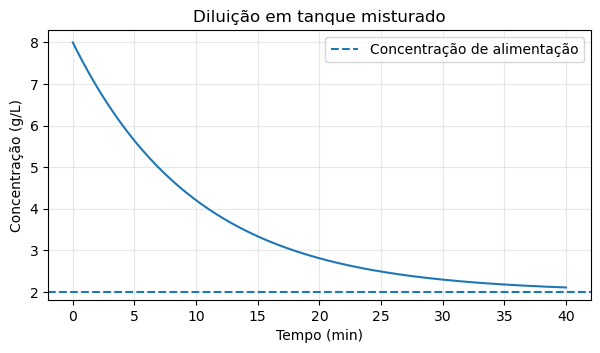

In [4]:
V = 100.0      # L
Q = 10.0       # L/min
Cin, C0 = 2.0, 8.0  # g/L
t = np.linspace(0, 40, 201)
C = Cin + (C0-Cin)*np.exp(-Q*t/V)
print(f"Concentração em 10 min: {Cin+(C0-Cin)*np.exp(-1):.4f} g/L")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, C)
ax.axhline(Cin, linestyle="--", label="Concentração de alimentação")
ax.set(xlabel="Tempo (min)", ylabel="Concentração (g/L)", title="Diluição em tanque misturado")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

**Interpretação:** a concentração se aproxima gradualmente da concentração de alimentação, sem atingi-la exatamente em tempo finito no modelo contínuo ideal.

<div id="secao-7" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">7. Balanço com reação química e estequiometria</div>

**Problema de Engenharia — Reação em batelada.** Para a reação idealizada $A\rightarrow B$, de primeira ordem em $A$, com volume constante e mistura perfeita,

$$\frac{dC_A}{dt}=-kC_A,\qquad \frac{dC_B}{dt}=kC_A.$$

Adotando $C_{A0}=1$ mol/L, $C_{B0}=0$ e $k=0{,}2$ min$^{-1}$, a solução é $C_A(t)=C_{A0}e^{-kt}$ e $C_B(t)=C_{A0}-C_A(t)$. Em 5 min, $C_A=e^{-1}\approx0{,}3679$ mol/L e $C_B\approx0{,}6321$ mol/L.

A relação $C_A+C_B=C_{A0}$ decorre da estequiometria 1:1 e das hipóteses adotadas; não é uma regra para reações arbitrárias.

Em 5 min: CA=0.3679; CB=0.6321 mol/L
Erro máximo de fechamento: 0.00e+00 mol/L


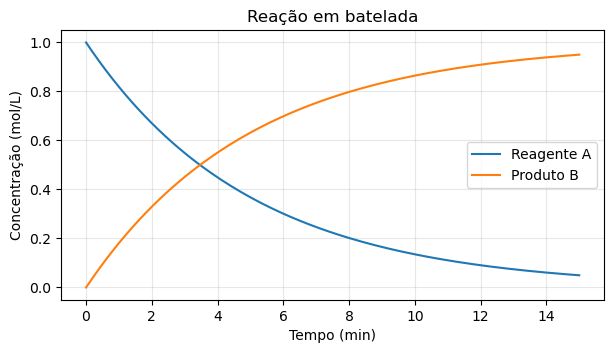

In [5]:
k_reacao = 0.2  # min^-1
CA0 = 1.0      # mol/L
t_reacao = np.linspace(0, 15, 151)
CA = CA0*np.exp(-k_reacao*t_reacao)
CB = CA0-CA
print(f"Em 5 min: CA={np.exp(-1):.4f}; CB={1-np.exp(-1):.4f} mol/L")
print(f"Erro máximo de fechamento: {np.max(np.abs(CA+CB-CA0)):.2e} mol/L")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t_reacao, CA, label="Reagente A")
ax.plot(t_reacao, CB, label="Produto B")
ax.set(xlabel="Tempo (min)", ylabel="Concentração (mol/L)", title="Reação em batelada")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

<div id="secao-8" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">8. Balanço de energia: conceitos e unidades</div>

O balanço de energia é uma aplicação da primeira lei da Termodinâmica. Em um volume de controle, devemos contabilizar energia armazenada, transportada por correntes, transferida como calor e trabalho, conforme as convenções de sinais adotadas.

Para os exemplos simplificados de aquecimento de líquido incompressível, desprezaremos variações de energia cinética e potencial, trabalho de eixo e efeitos de pressão relevantes. Com calor específico constante,

$$\Delta h\approx c_p\Delta T.$$

A expressão é uma aproximação de entalpia sensível; mudanças de fase, reação química e propriedades variáveis exigem termos adicionais. Uma diferença de temperatura em °C tem o mesmo valor numérico que em K.

<div id="secao-9" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">9. Aquecimento sensível em processo contínuo</div>

**Problema de Engenharia — Aquecimento contínuo.** Uma corrente líquida de $\dot m=2$ kg/s, com $c_p=4000$ J/(kg·K), é aquecida de 25 a 45 °C. Sem perdas térmicas e sem mudança de fase,

$$\dot Q=\dot m c_p(T_s-T_e).$$

A resolução manual fornece

$$\dot Q=2(4000)(45-25)=160000\ \mathrm{W}=160\ \mathrm{kW}.$$

A expressão representa a potência térmica **transferida ao fluido**, não necessariamente o consumo elétrico ou energético do equipamento.

In [6]:
m_kg_s = 2.0
cp_J_kg_K = 4000.0
T_entrada_C, T_saida_C = 25.0, 45.0
Q_W = m_kg_s*cp_J_kg_K*(T_saida_C-T_entrada_C)
print(f"Potência térmica: {Q_W/1000:.1f} kW")

Potência térmica: 160.0 kW


<div id="secao-10" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">10. Mistura adiabática de correntes</div>

**Problema de Engenharia — Mistura adiabática.** Duas correntes do **mesmo líquido**, com calor específico constante e igual, entram em um misturador termicamente isolado. Para $\dot m_1=2$ kg/s a 80 °C e $\dot m_2=3$ kg/s a 20 °C,

$$0=\dot m_1c_p(T_1-T_s)+\dot m_2c_p(T_2-T_s).$$

Como $c_p$ é o mesmo nas duas correntes, ele se cancela:

$$T_s=\frac{\dot m_1T_1+\dot m_2T_2}{\dot m_1+\dot m_2}=\frac{2(80)+3(20)}5=44\ ^\circ\mathrm{C}.$$

Se os fluidos ou calores específicos forem diferentes, é necessário formular o balanço de entalpia apropriado.

In [7]:
m1, m2 = 2.0, 3.0
T1, T2 = 80.0, 20.0
Ts = (m1*T1+m2*T2)/(m1+m2)
print(f"Temperatura de mistura: {Ts:.1f} °C")
assert min(T1,T2) <= Ts <= max(T1,T2)

Temperatura de mistura: 44.0 °C


<div id="secao-11" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">11. Balanço de energia em tanque aquecido</div>

**Problema de Engenharia — Tanque aquecido.** Um tanque perfeitamente misturado mantém massa constante $M=100$ kg, recebendo e descarregando $\dot m=1$ kg/min. O fluido entra a 20 °C; o tanque inicia a 20 °C e recebe potência térmica constante de 200 kJ/min. Admitindo $c_p=4$ kJ/(kg·K), sem perdas,

$$Mc_p\frac{dT}{dt}=\dot m c_p(T_{in}-T)+\dot Q.$$

Dividindo por $Mc_p$,

$$\frac{dT}{dt}=\frac{\dot m}{M}(T_{in}-T)+\frac{\dot Q}{Mc_p}.$$

No instante inicial, $dT/dt=200/(100\cdot4)=0{,}5$ °C/min. A temperatura estacionária prevista é $T_{ss}=T_{in}+\dot Q/(\dot m c_p)=70$ °C. A constante de tempo é $M/\dot m=100$ min.

<div id="secao-12" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">12. Simulação numérica com o método de Euler</div>

Para integrar a equação anterior numericamente, aplicaremos **Euler explícito**:

$$T_{n+1}=T_n+\Delta t\left[\frac{\dot m}{M}(T_{in}-T_n)+\frac{\dot Q}{Mc_p}\right].$$

Com $\Delta t=1$ min e $T_0=20$ °C, o primeiro passo manual é $T_1=20+1(0{,}5)=20{,}5$ °C. O passo deve ser escolhido de modo a representar a dinâmica e garantir estabilidade numérica.

In [8]:
M, mdot, cp = 100.0, 1.0, 4.0  # kg, kg/min, kJ/(kg K)
Tin, T0, Qdot = 20.0, 20.0, 200.0  # °C, °C, kJ/min
dt = 1.0  # min
t_euler = np.arange(0.0, 301.0, dt)
T_euler = np.empty_like(t_euler)
T_euler[0] = T0
def dTdt(T):
    return (mdot/M)*(Tin-T) + Qdot/(M*cp)
for i in range(len(t_euler)-1):
    T_euler[i+1] = T_euler[i] + dt*dTdt(T_euler[i])
print(f"Primeiro passo: {T_euler[1]:.3f} °C")
print(f"Em 300 min: {T_euler[-1]:.3f} °C")

Primeiro passo: 20.500 °C
Em 300 min: 67.548 °C


<div id="secao-13" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">13. Simulação com solve_ivp e verificação</div>

Podemos comparar o algoritmo de Euler com a solução analítica do modelo e com um integrador científico. Para o tanque aquecido,

$$T(t)=T_{ss}+(T_0-T_{ss})e^{-\dot m t/M}.$$

A biblioteca SciPy oferece `solve_ivp`, que implementa métodos de integração de equações diferenciais. Ela será usada **após** a formulação do balanço e a construção explícita do algoritmo. Se necessário, instale com `python -m pip install scipy`.

T(300) Euler: 67.5480 °C
T(300) solve_ivp: 67.5106 °C
T(300) analítica: 67.5106 °C
Erro máximo Euler: 0.0924 °C


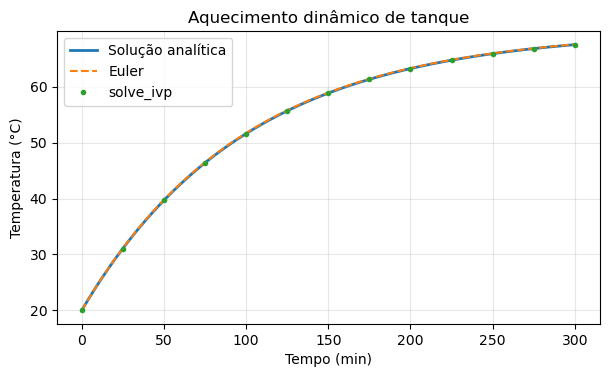

In [9]:
from scipy.integrate import solve_ivp
Tss = Tin + Qdot/(mdot*cp)
T_exata = Tss + (T0-Tss)*np.exp(-(mdot/M)*t_euler)
sol = solve_ivp(lambda t, y: [dTdt(y[0])],
                (t_euler[0], t_euler[-1]), [T0],
                t_eval=t_euler, rtol=1e-9, atol=1e-11)
if not sol.success:
    raise RuntimeError(sol.message)
print(f"T(300) Euler: {T_euler[-1]:.4f} °C")
print(f"T(300) solve_ivp: {sol.y[0,-1]:.4f} °C")
print(f"T(300) analítica: {T_exata[-1]:.4f} °C")
print(f"Erro máximo Euler: {np.max(np.abs(T_euler-T_exata)):.4f} °C")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(t_euler, T_exata, label="Solução analítica", linewidth=2)
ax.plot(t_euler, T_euler, "--", label="Euler")
ax.plot(t_euler[::25], sol.y[0,::25], "o", ms=3, label="solve_ivp")
ax.set(xlabel="Tempo (min)", ylabel="Temperatura (°C)", title="Aquecimento dinâmico de tanque")
ax.grid(alpha=0.3); ax.legend()
plt.show()

**Interpretação:** a temperatura cresce em direção a 70 °C. O acordo entre métodos é uma verificação numérica, mas a validade física depende das hipóteses sobre mistura, perdas e propriedades.

<div id="secao-14" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">14. Trocador de calor: balanços das correntes</div>

**Problema de Engenharia — Trocador de calor.** Uma corrente quente cede calor a uma corrente fria, sem troca térmica significativa com o ambiente. Considerando regime estacionário, ausência de mudança de fase e $c_p$ constantes,

$$\dot m_q c_{p,q}(T_{q,e}-T_{q,s})=\dot m_f c_{p,f}(T_{f,s}-T_{f,e}).$$

Considere a corrente quente com $\dot m_q=2$ kg/s, $c_{p,q}=4$ kJ/(kg·K), resfriando de 90 para 70 °C. A potência transferida é $2(4)(90-70)=160$ kJ/s = 160 kW. Para a corrente fria com $\dot m_f=4$ kg/s, $c_{p,f}=4$ kJ/(kg·K), entrando a 25 °C,

$$T_{f,s}=25+\frac{160}{4\cdot4}=35\ ^\circ\mathrm{C}.$$

O balanço de energia sozinho não determina a área de troca nem garante que o equipamento seja capaz de atingir essas temperaturas.

In [10]:
mq, cpq, Tqe, Tqs = 2.0, 4.0, 90.0, 70.0
mf, cpf, Tfe = 4.0, 4.0, 25.0
potencia_kW = mq*cpq*(Tqe-Tqs)
Tfs = Tfe + potencia_kW/(mf*cpf)
residuo_kW = mq*cpq*(Tqe-Tqs)-mf*cpf*(Tfs-Tfe)
print(f"Calor transferido: {potencia_kW:.1f} kW")
print(f"Temperatura de saída fria: {Tfs:.1f} °C")
print(f"Resíduo energético: {residuo_kW:.2e} kW")

Calor transferido: 160.0 kW
Temperatura de saída fria: 35.0 °C
Resíduo energético: 0.00e+00 kW


<div id="secao-15" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">15. Análise de sensibilidade e interpretação</div>

**Problema de Engenharia — Sensibilidade à vazão.** No mesmo trocador, mantenha a potência transferida de 160 kW e a temperatura de entrada fria em 25 °C, variando a vazão fria. Pela relação $T_{f,s}=T_{f,e}+\dot Q/(\dot m_f c_p)$, uma vazão menor exige maior elevação de temperatura para transportar a mesma potência.

Este é um estudo matemático de sensibilidade **com potência imposta**. Em um equipamento real, a potência pode variar com as vazões, as diferenças de temperatura e o coeficiente global de transferência.

Vazão fria = 3.0 kg/s -> T saída = 38.33 °C
Vazão fria = 4.0 kg/s -> T saída = 35.00 °C
Vazão fria = 5.0 kg/s -> T saída = 33.00 °C
Vazão fria = 6.0 kg/s -> T saída = 31.67 °C


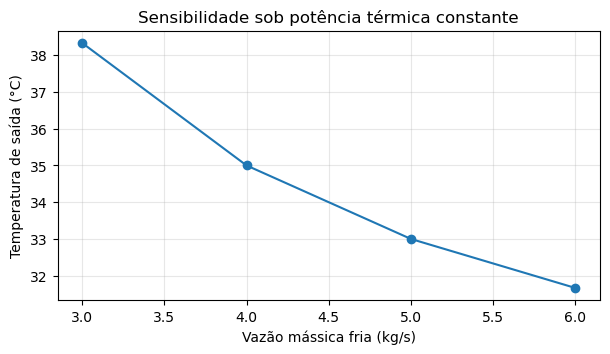

In [11]:
vazoes_frias = np.array([3.0, 4.0, 5.0, 6.0])  # kg/s
T_saida_fria = Tfe + potencia_kW/(vazoes_frias*cpf)
for vazao, temperatura in zip(vazoes_frias, T_saida_fria):
    print(f"Vazão fria = {vazao:.1f} kg/s -> T saída = {temperatura:.2f} °C")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(vazoes_frias, T_saida_fria, marker="o")
ax.set(xlabel="Vazão mássica fria (kg/s)", ylabel="Temperatura de saída (°C)", title="Sensibilidade sob potência térmica constante")
ax.grid(alpha=0.3)
plt.show()

<div id="secao-16" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">16. Validação física e erros frequentes</div>

Uma simulação só é útil quando seus resultados são coerentes com as leis físicas e com as hipóteses do modelo. Ao analisar balanços, verifique **unidades**, sinais, fechamento dos resíduos, valores iniciais, positividade de massas e volumes, limites de operação e compatibilidade entre o modelo e o processo.

Erros frequentes incluem confundir vazão volumétrica com mássica, usar calor específico em kJ/(kg·K) junto com potência em W sem conversão, omitir o termo de acúmulo em processos transientes e aplicar a expressão de mistura volumétrica a líquidos de propriedades muito diferentes.

A seguir, realizamos verificações simples. Elas não substituem a validação com dados experimentais.

In [12]:
assert np.all(volume_L > 0), "Volume não físico."
assert np.all(C >= 0), "Concentração negativa."
assert np.all(CA >= 0) and np.all(CB >= 0), "Concentração negativa."
assert abs(residuo_kW) < 1e-9, "Balanço energético não fecha."
assert abs(T_euler[0]-T0) < 1e-12, "Condição inicial incorreta."
print("Verificações básicas de consistência aprovadas.")

Verificações básicas de consistência aprovadas.


<div id="secao-17" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">17. Exercícios de consolidação</div>

**Exercício 1 — Balanço global.** Um equipamento recebe 250 kg/h e possui três saídas. Duas delas transportam 80 e 95 kg/h. Determine a terceira vazão e verifique o fechamento.

**Exercício 2 — Misturador.** Duas soluções, de 4 L/min a 12 g/L e 6 L/min a 3 g/L, são misturadas. Calcule a concentração de saída manualmente e em Python, explicitando as hipóteses.

**Exercício 3 — Tanque com nível variável.** Um tanque inicia com 80 L, recebe 7 L/min e descarrega 5 L/min. Calcule o volume após 15 min e explique a limitação do modelo.

**Exercício 4 — Diluição dinâmica.** Um tanque de volume constante de 50 L recebe e descarrega 5 L/min. Sua concentração inicial é 10 g/L e a alimentação possui 1 g/L. Deduzir a EDO e calcular a concentração após 10 min.

**Exercício 5 — Reação em batelada.** Para $A\rightarrow B$, com $k=0{,}1$ min$^{-1}$ e $C_{A0}=2$ mol/L, calcule $C_A$ e $C_B$ em 10 min. Verifique o fechamento estequiométrico.

**Exercício 6 — Aquecimento.** Uma corrente de 1,5 kg/s e $c_p=3{,}8$ kJ/(kg·K) é aquecida de 30 a 55 °C. Determine a potência térmica em kW.

**Exercício 7 — Mistura adiabática.** Duas correntes do mesmo líquido, com 1 kg/s a 70 °C e 2 kg/s a 25 °C, são misturadas. Determine a temperatura de saída.

**Exercício 8 — Trocador de calor.** Uma corrente quente de 1 kg/s, $c_p=4$ kJ/(kg·K), esfria de 85 para 65 °C. Uma corrente fria de 2 kg/s, com o mesmo $c_p$, entra a 20 °C. Determine sua temperatura de saída.

**Desafio integrador — Dinâmica térmica.** Modifique o modelo do tanque aquecido para incluir perda térmica $UA(T-T_a)$, em kJ/min. Escreva o balanço, implemente Euler e compare com `solve_ivp`, verificando unidades, sinais e comportamento estacionário.

<div id="secao-18" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">18. Conclusões</div>

Os exemplos demonstraram que a programação científica permite explorar o comportamento de processos químicos, mas a qualidade dos resultados depende da formulação dos balanços. Partimos das leis de conservação, resolvemos situações manualmente, implementamos os modelos e verificamos resultados com resíduos e comparações numéricas.

O próximo notebook aplicará a mesma metodologia a **Mecânica dos Fluidos com Python — Escoamento, Perda de Carga e Bombeamento**, aprofundando o uso de modelos físicos e cálculos computacionais em Engenharia.

<div style="text-align: center; font-size: 12px; color: gray; margin-top: 40px; padding-top: 15px; border-top: 1px solid #dddddd;">
Material desenvolvido pelo Grupo de Pesquisas em Modelagem Computacional da UESC.<br>
© 2026 — Todos os direitos reservados. Uso comercial somente mediante autorização.
</div>